In [1]:
# 1. Install CUDA-enabled PyTorch for Blackwell/RTX 50-series architecture
%pip install --upgrade torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu132

# 2. Install all Hugging Face and project dependencies
%pip install -U transformers datasets evaluate accelerate gradio scikit-learn pandas numpy

# 3. Verify CUDA detection and device capability
import random
import numpy as np
import pandas as pd
import torch
import transformers
import datasets
import evaluate
import accelerate
import gradio as gr

print(f"PyTorch Version: {torch.__version__}")
print(f"Transformers Version: {transformers.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Active Device: {torch.cuda.get_device_name(0)}")
    print(f"Compute Capability: {torch.cuda.get_device_capability(0)}")
    
else:
    print("WARNING: CUDA is not active. Check NVIDIA driver versions.")
    

Looking in indexes: https://download.pytorch.org/whl/cu132
Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.
PyTorch Version: 2.15.0+cu132
Transformers Version: 5.22.2
CUDA Available: True
Active Device: NVIDIA GeForce RTX 5060 Laptop GPU
Compute Capability: (12, 0)


In [2]:
try:
  import datasets, evaluate, accelerate
  import gradio as gr
except ModuleNotFoundError:
  !pip install -U datasets evaluate accelerate gradio # -U stands for "upgrade" so we'll get the latest version by default
  import datasets, evaluate, accelerate
  import gradio as gr

import random

import numpy as np
import pandas as pd

import torch
import transformers

print(f"Using transformers version: {transformers.__version__}")
print(f"Using datasets version: {datasets.__version__}")
print(f"Using torch version: {torch.__version__}")

Using transformers version: 5.22.2
Using datasets version: 5.1.0
Using torch version: 2.15.0+cu132


In [3]:
# Load the dataset from Hugging Face Hub
dataset = datasets.load_dataset(path="mrdbourke/learn_hf_food_not_food_image_captions")

# Inspect the dataset
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 250
    })
})

In [4]:
dataset.column_names

{'train': ['text', 'label']}

In [5]:
dataset["train"]

Dataset({
    features: ['text', 'label'],
    num_rows: 250
})

In [6]:
dataset["train"][0]

{'text': 'Creamy cauliflower curry with garlic naan, featuring tender cauliflower in a rich sauce with cream and spices, served with garlic naan bread.',
 'label': 'food'}

In [7]:
import random

random_indexs = random.sample(range(len(dataset["train"])), 5)
random_samples = dataset["train"][random_indexs]

print(f"[INFO] Random samples from dataset:\n")
for item in zip(random_samples["text"], random_samples["label"]):
    print(f"Text: {item[0]} | Label: {item[1]}")

[INFO] Random samples from dataset:

Text: Watching TV together, a family has their dog stretched out on the floor | Label: not_food
Text: Sushi with unique toppings like seared tuna or eel sauce. | Label: food
Text: Set of potholders stored in a drawer | Label: not_food
Text: Aromatic goat curry, featuring tender goat pieces in a flavorful sauce with spices, served with steamed basmati rice. | Label: food
Text: Set of knitting needles with yarn waiting to be knitted | Label: not_food


In [8]:
# Get unique label values
dataset["train"].unique("label")


['food', 'not_food']

In [9]:
from collections import Counter

Counter(dataset["train"]["label"])

Counter({'food': 125, 'not_food': 125})

In [10]:
# Turn our dataset into a DataFrame and get a random sample
food_not_food_df = pd.DataFrame(dataset["train"])
food_not_food_df.sample(7)

,text,label
0,"Creamy cauliflower curry with garlic naan, fea...",food
151,Round wooden dining table with chairs gathered...,not_food
74,Set of paintbrushes stored in a jar,not_food
34,Margherita pizza topped with fresh basil leave...,food
97,Telescope positioned on a balcony,not_food
220,Sewing machine ready for use on a table,not_food
204,"Tangy tomato curry with chicken, featuring ten...",food


In [11]:
food_not_food_df["label"].value_counts()

label
food        125
not_food    125
Name: count, dtype: int64

In [12]:
id2label = {0: "not_food", 1: "food"}
label2id = {"not_food": 0, "food": 1}

print(f"Label to ID mapping: {label2id}")
print(f"ID to Label mapping: {id2label}")


Label to ID mapping: {'not_food': 0, 'food': 1}
ID to Label mapping: {0: 'not_food', 1: 'food'}


In [13]:
# Create mappings programmatically from dataset
id2label = {idx: label for idx, label in enumerate(dataset["train"].unique("label")[::-1])} # reverse sort list to have "not_food" first
label2id = {label: idx for idx, label in id2label.items()}

print(f"Label to ID mapping: {label2id}")
print(f"ID to Label mapping: {id2label}")

Label to ID mapping: {'not_food': 0, 'food': 1}
ID to Label mapping: {0: 'not_food', 1: 'food'}


In [14]:
# Turn labels into 0 or 1 (e.g. 0 for "not_food", 1 for "food")
def map_labels_to_number(example):
  example["label"] = label2id[example["label"]]
  return example

example_sample = {"text": "This is a sentence about my favourite food: honey.", "label": "food"}

# Test the function
map_labels_to_number(example_sample)

{'text': 'This is a sentence about my favourite food: honey.', 'label': 1}

In [15]:
dataset = dataset["train"].map(map_labels_to_number)
dataset[:5]

{'text': ['Creamy cauliflower curry with garlic naan, featuring tender cauliflower in a rich sauce with cream and spices, served with garlic naan bread.',
  'Set of books stacked on a desk',
  'Watching TV together, a family has their dog stretched out on the floor',
  'Wooden dresser with a mirror reflecting the room',
  'Lawn mower stored in a shed'],
 'label': [1, 0, 0, 0, 0]}

In [16]:
# Shuffle the dataset and view the first 5 samples (will return different results each time)
dataset.shuffle()[:5]

{'text': ['A bowl of sliced honeydew with a sprinkle of salt and a side of prosciutto',
  'Green beans in a bowl, sprinkled with almonds and served with a side of lemon vinaigrette for a healthy, tasty dish.',
  'Friends having a barbecue in the backyard while pets play nearbyA collection of cleaning products under the sink',
  'Mouthwatering paneer tikka masala, featuring juicy paneer in a rich tomato-based sauce, garnished with fresh coriander leaves.',
  'Microwave oven ready for use on a kitchen counter'],
 'label': [1, 1, 0, 1, 0]}

In [17]:
dataset = dataset.train_test_split(test_size=0.2, seed=42) # note: seed isn't needed, just here for reproducibility, without it you will get different splits each time you run the cell
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 200
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 50
    })
})

In [18]:
random_idx_train = random.randint(0, len(dataset["train"]))
random_sample_train = dataset["train"][random_idx_train]

random_idx_test = random.randint(0, len(dataset["test"]))
random_sample_test = dataset["test"][random_idx_test]

print(f"[INFO] Random sample from training dataset:")
print(f"Text: {random_sample_train['text']}\nLabel: {random_sample_train['label']} ({id2label[random_sample_train['label']]})\n")
print(f"[INFO] Random sample from testing dataset:")
print(f"Text: {random_sample_test['text']}\nLabel: {random_sample_test['label']} ({id2label[random_sample_test['label']]})")

[INFO] Random sample from training dataset:
Text: Set of mixing bowls perched on a shelf
Label: 0 (not_food)

[INFO] Random sample from testing dataset:
Text: Sushi with a spicy kick, featuring jalapeno peppers or spicy mayo.
Label: 1 (food)


In [19]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name_or_path="distilbert/distilbert-base-uncased",
                                          use_fast=True) # uses fast tokenization (backed by tokenziers library and implemented in Rust) by default, if not available will default to Python implementation

tokenizer

BertTokenizer(name_or_path='distilbert/distilbert-base-uncased', vocab_size=30522, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})

In [20]:
# Test out tokenizer
tokenizer("I love pizza")

{'input_ids': [101, 1045, 2293, 10733, 102], 'token_type_ids': [0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1]}

In [21]:
# Try adding a "!" at the end
tokenizer("I love pizza!")

{'input_ids': [101, 1045, 2293, 10733, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1]}

In [22]:
# Get the length of the vocabulary
length_of_tokenizer_vocab = len(tokenizer.vocab)
print(f"Length of tokenizer vocabulary: {length_of_tokenizer_vocab}")

# Get the maximum sequence length the tokenizer can handle
max_tokenizer_input_sequence_length = tokenizer.model_max_length
print(f"Max tokenizer input sequence length: {max_tokenizer_input_sequence_length}")

Length of tokenizer vocabulary: 30522
Max tokenizer input sequence length: 512


In [23]:
# Does "daniel" occur in the vocab?
tokenizer.vocab["daniel"]

3817

In [24]:
tokenizer.convert_ids_to_tokens(tokenizer("akash").input_ids)

['[CLS]', 'aka', '##sh', '[SEP]']

In [25]:
# Try to tokenize an emoji
tokenizer.convert_ids_to_tokens(tokenizer("🍕").input_ids)

['[CLS]', '[UNK]', '[SEP]']

In [26]:
# Get the first 5 items in the tokenizer vocab
sorted(tokenizer.vocab.items())[:5]

[('!', 999), ('"', 1000), ('#', 1001), ('##!', 29612), ('##"', 29613)]

In [27]:
import random

random.sample(sorted(tokenizer.vocab.items()), k=5)


[('champ', 24782),
 ('jacket', 6598),
 ('teacher', 3836),
 ('teach', 6570),
 ('sr', 5034)]

In [28]:
def tokenize_text(examples):
    """
    Tokenize given example text and return the tokenized text.
    """
    return tokenizer(examples["text"],
                     padding=True, # pad short sequences to longest sequence in the batch
                     truncation=True) # truncate long sequences to the maximum length the model can handle

In [29]:
example_sample_2 = {"text": "I love pizza", "label": 1}

# Test the function
tokenize_text(example_sample_2)

{'input_ids': [101, 1045, 2293, 10733, 102], 'token_type_ids': [0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1]}

In [30]:
# Map our tokenize_text function to the dataset
tokenized_dataset = dataset.map(function=tokenize_text,
                                batched=True, # set batched=True to operate across batches of examples rather than only single examples
                                batch_size=1000) # defaults to 1000, can be increased if you have a large dataset

tokenized_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 200
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 50
    })
})

In [31]:
# Get two samples from the tokenized dataset
train_tokenized_sample = tokenized_dataset["train"][0]
test_tokenized_sample = tokenized_dataset["test"][0]

for key in train_tokenized_sample.keys():
    print(f"[INFO] Key: {key}")
    print(f"Train sample: {train_tokenized_sample[key]}")
    print(f"Test sample: {test_tokenized_sample[key]}")
    print("")

[INFO] Key: text
Train sample: Set of headphones placed on a desk
Test sample: A slice of pepperoni pizza with a layer of melted cheese

[INFO] Key: label
Train sample: 0
Test sample: 1

[INFO] Key: input_ids
Train sample: [101, 2275, 1997, 2132, 19093, 2872, 2006, 1037, 4624, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Test sample: [101, 1037, 14704, 1997, 11565, 10698, 10733, 2007, 1037, 6741, 1997, 12501, 8808, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

[INFO] Key: token_type_ids
Train sample: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Test sample: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

[INFO] Key: attention_mask
Train sample: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Test sample: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0

In [32]:
import evaluate
import numpy as np
from typing import Tuple

accuracy_metric = evaluate.load("accuracy")

def compute_accuracy(predictions_and_labels: Tuple[np.array, np.array]):
  """
  Computes the accuracy of a model by comparing the predictions and labels.
  """
  predictions, labels = predictions_and_labels

  # Get highest prediction probability of each prediction if predictions are probabilities
  if len(predictions.shape) >= 2:
    predictions = np.argmax(predictions, axis=1)

  return accuracy_metric.compute(predictions=predictions, references=labels)

Using the latest cached version of the module from C:\Users\muham\.cache\huggingface\modules\evaluate_modules\metrics\evaluate-metric--accuracy\f887c0aab52c2d38e1f8a215681126379eca617f96c447638f751434e8e65b14 (last modified on Sun Nov  8 18:16:48 2026) since it couldn't be found locally at evaluate-metric--accuracy, or remotely on the Hugging Face Hub.


In [33]:
# Get id and label mappings
print(f"id2label: {id2label}")
print(f"label2id: {label2id}")

id2label: {0: 'not_food', 1: 'food'}
label2id: {'not_food': 0, 'food': 1}


In [34]:
from transformers import AutoModelForSequenceClassification

# Setup model for fine-tuning with classification head (top layers of network)
model = AutoModelForSequenceClassification.from_pretrained(
    pretrained_model_name_or_path="distilbert/distilbert-base-uncased",
    num_labels=2, # can customize this to the number of classes in your dataset
    id2label=id2label, # mappings from class IDs to the class labels (for classification tasks)
    label2id=label2id
)

Could not reach the Hub ([WinError 10054] An existing connection was forcibly closed by the remote host). Using cached commit hash for 'distilbert/distilbert-base-uncased'.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [35]:
model

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

In [36]:
def count_params(model):
    """
    Count the parameters of a PyTorch model.
    """
    trainable_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_parameters = sum(p.numel() for p in model.parameters())

    return {"trainable_parameters": trainable_parameters, "total_parameters": total_parameters}

# Count the parameters of the model
count_params(model)

{'trainable_parameters': 66955010, 'total_parameters': 66955010}

In [37]:
# Create model output directory
from pathlib import Path

# Create models directory
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

# Create model save name
model_save_name = "learn_hf_food_not_food_text_classifier-distilbert-base-uncased"

# Create model save path
model_save_dir = Path(models_dir, model_save_name)

model_save_dir

WindowsPath('models/learn_hf_food_not_food_text_classifier-distilbert-base-uncased')

In [38]:
from transformers import TrainingArguments

print(f"[INFO] Saving model checkpoints to: {model_save_dir}")

# Create training arguments
training_args = TrainingArguments(
    output_dir=model_save_dir,
    learning_rate=0.0001,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=10,
    eval_strategy="epoch", # was previously "evaluation_strategy"
    save_strategy="epoch",
    save_total_limit=3, # limit the total amount of save checkpoints (so we don't save num_epochs checkpoints)
    use_cpu=False, # set to False by default, will use CUDA GPU or MPS device if available
    seed=42, # set to 42 by default for reproducibility
    load_best_model_at_end=True, # load the best model when finished training
    logging_strategy="epoch", # log training results every epoch
    report_to="none", # optional: log experiments to Weights & Biases/other similar experimenting tracking services (we'll turn this off for now)
    # push_to_hub=True # optional: automatically upload the model to the Hub (we'll do this manually later on)
    # hub_token="your_token_here" # optional: add your Hugging Face Hub token to push to the Hub (will default to huggingface-cli login)
    hub_private_repo=False # optional: make the uploaded model private (defaults to False)
)

# Optional: Print out training_args to inspect (warning, it is quite a long output)
training_args

[INFO] Saving model checkpoints to: models\learn_hf_food_not_food_text_classifier-distilbert-base-uncased


TrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=None,
dataloader_drop_last=False,
dataloader_in_order=True,
dataloader_multiprocessing_context=None,
dataloader_num_workers=0,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_static_graph=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=True,
do_predict=False,
do_train=False,
enable_jit_checkpoint=False,
eval_accumulation_steps=None,
eval_delay=0,
eval_do_concat_batches=True,
eval_on_start

In [39]:
from transformers import Trainer
# Setup Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    processing_class=tokenizer, # Pass tokenizer to the Trainer as processing_class in Transformers v5.x
    compute_metrics=compute_accuracy
)

In [40]:
# Train a text classification model
results = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.437548,0.089838,1.000000
2,0.047484,0.009997,1.000000
3,0.006784,0.003061,1.000000
4,0.002547,0.001588,1.000000
5,0.001491,0.001074,1.000000
6,0.001124,0.000852,1.000000
7,0.000947,0.000737,1.000000
8,0.000798,0.000676,1.000000
9,0.000766,0.000644,1.000000
10,0.000694,0.000634,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [41]:
# Inspect training metrics
for key, value in results.metrics.items():
    print(f"{key}: {value}")
     

train_runtime: 16.2522
train_samples_per_second: 123.06
train_steps_per_second: 4.307
total_flos: 18110777160000.0
train_loss: 0.05001808109560183
epoch: 10.0


In [42]:
# Save model
print(f"[INFO] Saving model to {model_save_dir}")
trainer.save_model(output_dir=model_save_dir)

[INFO] Saving model to models\learn_hf_food_not_food_text_classifier-distilbert-base-uncased


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [43]:
# Get training history 
trainer_history_all = trainer.state.log_history 
trainer_history_metrics = trainer_history_all[:-1] # get everything except the training time metrics (we've seen these already)
trainer_history_training_time = trainer_history_all[-1] # this is the same value as results.metrics from above

# View the first 4 metrics from the training history
trainer_history_metrics[:4]

[{'loss': 0.43754799025399344,
  'grad_norm': 1.8109395503997803,
  'learning_rate': 9.142857142857143e-05,
  'epoch': 1.0,
  'step': 7},
 {'eval_loss': 0.08983790129423141,
  'eval_accuracy': 1.0,
  'eval_runtime': 0.0513,
  'eval_samples_per_second': 975.17,
  'eval_steps_per_second': 39.007,
  'epoch': 1.0,
  'step': 7},
 {'loss': 0.04748377203941345,
  'grad_norm': 0.22037459909915924,
  'learning_rate': 8.142857142857143e-05,
  'epoch': 2.0,
  'step': 14},
 {'eval_loss': 0.009997360408306122,
  'eval_accuracy': 1.0,
  'eval_runtime': 0.0553,
  'eval_samples_per_second': 903.773,
  'eval_steps_per_second': 36.151,
  'epoch': 2.0,
  'step': 14}]

In [44]:
import pprint # import pretty print for nice printing of lists

# Extract training and evaluation metrics
trainer_history_training_set = []
trainer_history_eval_set = []

# Loop through metrics and filter for training and eval metrics
for item in trainer_history_metrics:
    item_keys = list(item.keys())
    # Check to see if "eval" is in the keys of the item
    if any("eval" in item for item in item_keys):
        trainer_history_eval_set.append(item)
    else:
        trainer_history_training_set.append(item)

# Show the first two items in each metric set
print(f"[INFO] First two items in training set:")
pprint.pprint(trainer_history_training_set[:2])

print(f"\n[INFO] First two items in evaluation set:")
pprint.pprint(trainer_history_eval_set[:2])

[INFO] First two items in training set:
[{'epoch': 1.0,
  'grad_norm': 1.8109395503997803,
  'learning_rate': 9.142857142857143e-05,
  'loss': 0.43754799025399344,
  'step': 7},
 {'epoch': 2.0,
  'grad_norm': 0.22037459909915924,
  'learning_rate': 8.142857142857143e-05,
  'loss': 0.04748377203941345,
  'step': 14}]

[INFO] First two items in evaluation set:
[{'epoch': 1.0,
  'eval_accuracy': 1.0,
  'eval_loss': 0.08983790129423141,
  'eval_runtime': 0.0513,
  'eval_samples_per_second': 975.17,
  'eval_steps_per_second': 39.007,
  'step': 7},
 {'epoch': 2.0,
  'eval_accuracy': 1.0,
  'eval_loss': 0.009997360408306122,
  'eval_runtime': 0.0553,
  'eval_samples_per_second': 903.773,
  'eval_steps_per_second': 36.151,
  'step': 14}]


In [45]:
# Create pandas DataFrames for the training and evaluation metrics
trainer_history_training_df = pd.DataFrame(trainer_history_training_set)
trainer_history_eval_df = pd.DataFrame(trainer_history_eval_set)

trainer_history_training_df.head() 

,loss,grad_norm,learning_rate,epoch,step
0,0.437548,1.810940,0.000091,1.0,7
1,0.047484,0.220375,0.000081,2.0,14
2,0.006784,0.061040,0.000071,3.0,21
3,0.002547,0.029517,0.000061,4.0,28
4,0.001491,0.018154,0.000051,5.0,35


In [46]:
trainer_history_eval_df.head()

,eval_loss,eval_accuracy,eval_runtime,eval_samples_per_second,eval_steps_per_second,epoch,step
0,0.089838,1.0,0.0513,975.170,39.007,1.0,7
1,0.009997,1.0,0.0553,903.773,36.151,2.0,14
2,0.003061,1.0,0.0524,953.684,38.147,3.0,21
3,0.001588,1.0,0.0530,943.265,37.731,4.0,28
4,0.001074,1.0,0.0514,971.997,38.880,5.0,35


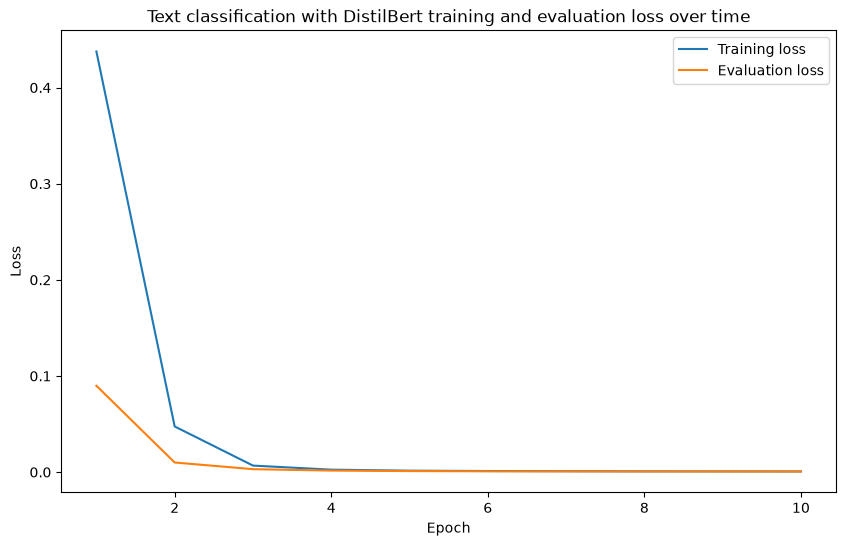

In [47]:
# Plot training and evaluation loss
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(trainer_history_training_df["epoch"], trainer_history_training_df["loss"], label="Training loss")
plt.plot(trainer_history_eval_df["epoch"], trainer_history_eval_df["eval_loss"], label="Evaluation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Text classification with DistilBert training and evaluation loss over time")
plt.legend()
plt.show()

In [48]:
from huggingface_hub import login

login()

In [49]:
from huggingface_hub import HfApi

api = HfApi()

# 1. Create the repository on your account
api.create_repo(
    repo_id="MS260000/food-not-food-text-classifier",
    repo_type="model",
    exist_ok=True
)

# 2. Upload the entire local model folder
api.upload_folder(
    folder_path=str(model_save_dir),
    repo_id="MS260000/food-not-food-text-classifier",
    commit_message="Uploading food not food text classifier model"
)

CommitInfo(commit_url='https://huggingface.co/MS260000/food-not-food-text-classifier/commit/d62143392be9c64b9b8096d155a22af2e3c485a3', commit_message='Uploading food not food text classifier model', commit_description='', oid='d62143392be9c64b9b8096d155a22af2e3c485a3', pr_url=None, repo_url=RepoUrl('https://huggingface.co/MS260000/food-not-food-text-classifier', endpoint='https://huggingface.co', repo_type='model', repo_id='MS260000/food-not-food-text-classifier'), pr_revision=None, pr_num=None)

In [50]:
# Perform predictions on the test set
predictions_all = trainer.predict(tokenized_dataset["test"])
prediction_values = predictions_all.predictions
prediction_metrics = predictions_all.metrics

print(f"[INFO] Prediction metrics on the test data:")
prediction_metrics

[INFO] Prediction metrics on the test data:


{'test_loss': 0.0006335979560390115,
 'test_accuracy': 1.0,
 'test_runtime': 0.1333,
 'test_samples_per_second': 375.055,
 'test_steps_per_second': 15.002}

In [51]:
import torch
from sklearn.metrics import accuracy_score

# 1. Get prediction probabilities (this is optional, could get the same results with step 2 onwards)
pred_probs = torch.softmax(torch.tensor(prediction_values), dim=1)

# 2. Get the predicted labels
pred_labels = torch.argmax(pred_probs, dim=1)

# 3. Get the true labels
true_labels = dataset["test"]["label"]

# 4. Compare predicted labels to true labels to get the test accuracy
test_accuracy = accuracy_score(y_true=true_labels, 
                               y_pred=pred_labels)

print(f"[INFO] Test accuracy: {test_accuracy*100}%")

[INFO] Test accuracy: 100.0%


In [52]:
# Make a DataFrame of test predictions
test_predictions_df = pd.DataFrame({
    "text": dataset["test"]["text"],
    "true_label": true_labels,
    "pred_label": pred_labels,
    "pred_prob": torch.max(pred_probs, dim=1).values
})

test_predictions_df.head()

,text,true_label,pred_label,pred_prob
0,A slice of pepperoni pizza with a layer of mel...,1,1,0.999323
1,Red brick fireplace with a mantel serving as a...,0,0,0.999451
2,A bowl of sliced bell peppers with a sprinkle ...,1,1,0.999323
3,Set of mugs hanging on a hook,0,0,0.999500
4,Standing floor lamp providing light next to an...,0,0,0.999483


In [53]:
# Show 10 examples with low prediction probability
test_predictions_df.sort_values("pred_prob", ascending=True).head(10)

,text,true_label,pred_label,pred_prob
40,A bowl of cherries with a sprig of mint for ga...,1,1,0.999131
14,Two handfuls of bananas in a fruit bowl with g...,1,1,0.999294
31,Crunchy sushi roll with tempura flakes or pank...,1,1,0.999295
11,A close-up shot of a cheesy pizza slice being ...,1,1,0.999300
18,Traditional Japanese flavored sushi roll with ...,1,1,0.999301
26,A fruit platter with a variety of exotic fruit...,1,1,0.999301
49,Plate of sushi served with pickled ginger and ...,1,1,0.999304
46,A bowl of sliced kiwi with a sprinkle of sugar...,1,1,0.999304
20,"Pizza with a seafood theme, featuring toppings...",1,1,0.999305
35,Luxurious coconut shrimp curry on a generous p...,1,1,0.999308


In [74]:
huggingface_model_path = "ms260000/food-not-food-text-classifier"

In [55]:
def set_device():
    """
    Set device to CUDA if available, else MPS (Mac), else CPU.

    This defaults to using the best available device (usually).
    """
    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif torch.backends.mps.is_available() and torch.backends.mps.is_built():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
    return device

DEVICE = set_device()
print(f"[INFO] Using device: {DEVICE}")

[INFO] Using device: cuda


In [57]:
import torch
from transformers import pipeline

BATCH_SIZE = 32

food_not_food_classifier = pipeline(
    task="text-classification",
    model="MS260000/food-not-food-text-classifier",
    tokenizer="MS260000/food-not-food-text-classifier",
    device=0 if torch.cuda.is_available() else -1,  # 0 for GPU index, -1 for CPU
    top_k=1,
    batch_size=BATCH_SIZE,
)

food_not_food_classifier

config.json:   0%|          | 0.00/812 [00:00<?, ?B/s]

d:\Anaconda\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\muham\.cache\huggingface\hub\models--MS260000--food-not-food-text-classifier. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
d:\Anaconda\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses s

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

TextClassificationPipeline: {'model': 'DistilBertForSequenceClassification', 'dtype': 'float32', 'device': 'cuda', 'input_modalities': 'text'}

In [59]:
# Test our trained model on some example text 
sample_text_food = "A delicious photo of a plate of scrambled eggs, bacon and toast"
food_not_food_classifier(sample_text_food)

[[{'label': 'food', 'score': 0.9992668032646179}]]

In [60]:
# Test the model on some more example text
sample_text_not_food = "A yellow tractor driving over the hill"
food_not_food_classifier(sample_text_not_food)

[[{'label': 'not_food', 'score': 0.9994624257087708}]]

In [61]:
# Pass in random text to the model
food_not_food_classifier("cvnhertiejhwgdjshdfgh394587")

[[{'label': 'not_food', 'score': 0.9954851865768433}]]

In [62]:
# Pipeline also works with remote models
food_not_food_classifier_remote = pipeline(
    task="text-classification",
    model="MS260000/food-not-food-text-classifier",  # Use "username/repo_name" instead of the full URL
    batch_size=BATCH_SIZE,
    device=0
)

food_not_food_classifier_remote("This is some new text about bananas and pancakes and ice cream")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'food', 'score': 0.9992714524269104}]

In [63]:
# Create batch size (we don't need to do this again but we're doing it for clarity)
BATCH_SIZE = 32 # this number is experimental and will require testing on your hardware to find the optimal value (e.g. lower if there are memory issues or higher to try speed up inference)

# Setup pipeline to handle batches (we don't need to do this again either but we're doing it for clarity)
food_not_food_classifier = pipeline(task="text-classification", 
                                    model="ms260000/food-not-food-text-classifier",
                                    batch_size=BATCH_SIZE,
                                    device=0 if torch.cuda.is_available() else -1) # 0 for GPU index, -1 for CPU

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [64]:
# Create a list of sentences to make predictions on
sentences = [
    "I whipped up a fresh batch of code, but it seems to have a syntax error.",
    "We need to marinate these ideas overnight before presenting them to the client.",
    "The new software is definitely a spicy upgrade, taking some time to get used to.",
    "Her social media post was the perfect recipe for a viral sensation.",
    "He served up a rebuttal full of facts, leaving his opponent speechless.",
    "The team needs to simmer down a bit before tackling the next challenge.",
    "The presentation was a delicious blend of humor and information, keeping the audience engaged.",
    "A beautiful array of fake wax foods (shokuhin sampuru) in the front of a Japanese restaurant.",
    "Daniel Bourke is really cool :D",
    "My favoruite food is biltong!"
]

food_not_food_classifier(sentences)

[{'label': 'not_food', 'score': 0.9973496198654175},
 {'label': 'not_food', 'score': 0.9968788623809814},
 {'label': 'not_food', 'score': 0.993787407875061},
 {'label': 'not_food', 'score': 0.9928838014602661},
 {'label': 'not_food', 'score': 0.9950113296508789},
 {'label': 'not_food', 'score': 0.9950450658798218},
 {'label': 'not_food', 'score': 0.9736484885215759},
 {'label': 'food', 'score': 0.9991556406021118},
 {'label': 'not_food', 'score': 0.9987936019897461},
 {'label': 'not_food', 'score': 0.9938684105873108}]

In [65]:
import time

# Create 1000 sentences
sentences_1000 = sentences * 100

# Time how long it takes to make predictions on all sentences (one at a time)
print(f"[INFO] Number of sentences: {len(sentences_1000)}")
start_time_one_at_a_time = time.time()
for sentence in sentences_1000:
    # Make a prediction on each sentence one at a time
    food_not_food_classifier(sentence)
end_time_one_at_a_time = time.time()

print(f"[INFO] Time taken for one at a time prediction: {end_time_one_at_a_time - start_time_one_at_a_time} seconds")
print(f"[INFO] Avg inference time per sentence: {(end_time_one_at_a_time - start_time_one_at_a_time) / len(sentences_1000)} seconds")

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


[INFO] Number of sentences: 1000
[INFO] Time taken for one at a time prediction: 4.9652955532073975 seconds
[INFO] Avg inference time per sentence: 0.004965295553207397 seconds


In [66]:
for i in [10, 100, 1000, 10_000]:
    sentences_big = sentences * i
    print(f"[INFO] Number of sentences: {len(sentences_big)}")

    start_time = time.time()
    # Predict on all sentences in batches 
    food_not_food_classifier(sentences_big)
    end_time = time.time()

    print(f"[INFO] Inference time for {len(sentences_big)} sentences: {round(end_time - start_time, 5)} seconds.")
    print(f"[INFO] Avg inference time per sentence: {round((end_time - start_time) / len(sentences_big), 8)} seconds.")
    print()

[INFO] Number of sentences: 100
[INFO] Inference time for 100 sentences: 0.20396 seconds.
[INFO] Avg inference time per sentence: 0.0020396 seconds.

[INFO] Number of sentences: 1000
[INFO] Inference time for 1000 sentences: 0.59092 seconds.
[INFO] Avg inference time per sentence: 0.00059092 seconds.

[INFO] Number of sentences: 10000
[INFO] Inference time for 10000 sentences: 6.0371 seconds.
[INFO] Avg inference time per sentence: 0.00060371 seconds.

[INFO] Number of sentences: 100000
[INFO] Inference time for 100000 sentences: 76.26874 seconds.
[INFO] Avg inference time per sentence: 0.00076269 seconds.



In [67]:
from transformers import AutoTokenizer

# Setup model path (can be local or on Hugging Face)
# Note: Be sure to change "mrdbourke" to your own username
model_path = "ms260000/food-not-food-text-classifier"
 
# Create an example to predict on
sample_text_food = "A delicious photo of a plate of scrambled eggs, bacon and toast"

# Prepare the tokenizer and tokenize the inputs
tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name_or_path=model_path)
inputs = tokenizer(sample_text_food, 
                   return_tensors="pt") # return the output as PyTorch tensors 
inputs

{'input_ids': tensor([[  101,  1037, 12090,  6302,  1997,  1037,  5127,  1997, 13501,  6763,
          1010, 11611,  1998, 15174,   102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [68]:
from transformers import AutoModelForSequenceClassification

# Load our text classification model
model = AutoModelForSequenceClassification.from_pretrained(pretrained_model_name_or_path=model_path)

Could not reach the Hub ([WinError 10054] An existing connection was forcibly closed by the remote host). Using cached commit hash for 'ms260000/food-not-food-text-classifier'.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [69]:
import torch

with torch.no_grad():
    outputs = model(**inputs) # '**' means input all of the dictionary keys as arguments to the function
    # outputs = model(input_ids=inputs["input_ids"],
    #                 attention_mask=inputs["attention_mask"]) # same as above, but explicitly passing in the keys

outputs

SequenceClassifierOutput(loss=None, logits=tensor([[-3.7157,  3.5018]]), hidden_states=None, attentions=None)

In [70]:
# Get predicted class and prediction probability
predicted_class_id = outputs.logits.argmax().item()
prediction_probability = torch.softmax(outputs.logits, dim=1).max().item()

print(f"Text: {sample_text_food}")
print(f"Predicted label: {model.config.id2label[predicted_class_id]}")
print(f"Prediction probability: {prediction_probability}")

Text: A delicious photo of a plate of scrambled eggs, bacon and toast
Predicted label: food
Prediction probability: 0.9992668032646179


In [76]:
import torch

from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_path = "MS260000/food-not-food-text-classifier"

# Load the model and tokenizer
tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name_or_path=model_path)
model = AutoModelForSequenceClassification.from_pretrained(pretrained_model_name_or_path=model_path)

# Make sample text and tokenize it
sample_text = "A photo of a broccoli, salmon, rice and radish dish"
inputs = tokenizer(sample_text, return_tensors="pt")

# Make a prediction
with torch.no_grad():
    outputs = model(**inputs)

# Get predicted class and prediction probability
output_logits = outputs.logits
predicted_class_id = torch.argmax(output_logits, dim=1).item()
predicted_class_label = model.config.id2label[predicted_class_id]
predicted_probability = torch.softmax(output_logits, dim=1).max().item()

# Print outputs
print(f"Text: {sample_text}")
print(f"Predicted class: {predicted_class_label} (prob: {predicted_probability * 100:.2f}%)")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Text: A photo of a broccoli, salmon, rice and radish dish
Predicted class: food (prob: 99.93%)


In [78]:
from typing import Dict

# 1. Create a function which takes text as input 
def food_not_food_classifier(text: str) -> Dict[str, float]:
    """
    Takes an input string of text and classifies it into food/not_food in the form of a dictionary.
    """

    # 2. Setup the pipeline to use the local model (or Hugging Face model path)
    food_not_food_classifier = pipeline(task="text-classification", 
                                        model="MS260000/food-not-food-text-classifier",
                                        batch_size=32,
                                        device="cuda" if torch.cuda.is_available() else "cpu", # set the device to work in any environment
                                        top_k=None) # return all possible scores (not just top-1)
    
    # 3. Get outputs from pipeline (as a list of dicts)
    outputs = food_not_food_classifier(text)[0]
    
    # 4. Format output for Gradio (e.g. {"label_1": probability_1, "label_2": probability_2})
    output_dict = {}
    for item in outputs:
        output_dict[item["label"]] = item["score"]

    return output_dict

# Test out the function
food_not_food_classifier("My lunch today was chicken and salad")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

{'food': 0.9983841180801392, 'not_food': 0.0016158766811713576}

In [81]:
from pathlib import Path

# Make a directory for demos
demos_dir = Path("demos")
demos_dir.mkdir(exist_ok=True)

# Create a folder for the food_not_food_text_classifer demo
food_not_food_text_classifier_demo_dir = Path(demos_dir, "food_not_food_text_classifier")
food_not_food_text_classifier_demo_dir.mkdir(exist_ok=True)

In [82]:
%%writefile demos/food_not_food_text_classifier/app.py
import gradio as gr
from typing import Dict
from transformers import pipeline

# Load pipeline globally once on CPU to avoid ZeroGPU checks and startup hangs
food_not_food_pipeline = pipeline(
    task="text-classification", 
    model="MS260000/food-not-food-text-classifier",
    device="cpu",
    top_k=None
)

def food_not_food_classifier(text: str) -> Dict[str, float]:
    outputs = food_not_food_pipeline(text)[0]
    output_dict = {}
    for item in outputs:
        output_dict[item["label"]] = item["score"]
    return output_dict

description = """
A text classifier to determine if a sentence is about food or not food. 

Fine-tuned from [DistilBERT](/MS260000/food-not-food-text-classifier) on a [small dataset of food and not food text](https://huggingface.co/MS260000/food-not-food-text-classifier).
"""

demo = gr.Interface(
    fn=food_not_food_classifier, 
    inputs="text", 
    outputs=gr.Label(num_top_classes=2),
    title="🍗🚫🥑 Food or Not Food Text Classifier",
    description=description,
    examples=[
        ["I whipped up a fresh batch of code, but it seems to have a syntax error."],
        ["A delicious photo of a plate of scrambled eggs, bacon and toast."]
    ]
)

if __name__ == "__main__":
    demo.launch()

Writing demos/food_not_food_text_classifier/app.py


In [83]:
%%writefile demos/food_not_food_text_classifier/requirements.txt
gradio
torch
transformers

Writing demos/food_not_food_text_classifier/requirements.txt


In [84]:
%%writefile demos/food_not_food_text_classifier/README.md
---
title: Food Not Food Text Classifier
emoji: 🍗🚫🥑
colorFrom: blue
colorTo: yellow
sdk: gradio
app_file: app.py
pinned: false
license: apache-2.0
---

# 🍗🚫🥑 Food Not Food Text Classifier

Small demo to showcase a text classifier to determine if a sentence is about food or not food.

DistillBERT model fine-tuned on a small synthetic dataset of 250 generated [Food or Not Food image captions](https://huggingface.co/MS260000/food-not-food-text-classifier/tree/main).

[Source code notebook]().

Writing demos/food_not_food_text_classifier/README.md


In [88]:
from huggingface_hub import create_repo
create_repo(FULL_REPO_ID, repo_type="space", space_sdk="gradio", exist_ok=True)

HfHubHTTPError: Client error '402 Payment Required' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-6af10da1-46ae251d5d1ab5b4266d3d45;c20fc38f-71d4-4549-9e1a-6422425bdfce)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

Static Spaces are free for everyone, but hosting Gradio and Docker Spaces on free cpu-basic requires a PRO subscription. Subscribe at https://huggingface.co/pro

In [85]:
import time
from pathlib import Path
from huggingface_hub import upload_file

LOCAL_DEMO_FOLDER = Path("demos/food_not_food_text_classifier")
FULL_REPO_ID = "MS260000/food-not-food-text-classifier"

files_to_upload = ["README.md", "requirements.txt", "app.py"]

for filename in files_to_upload:
    file_path = LOCAL_DEMO_FOLDER / filename
    if not file_path.exists():
        print(f"[WARN] {filename} not found, skipping...")
        continue
    
    success = False
    for attempt in range(1, 4):
        try:
            print(f"[INFO] Uploading {filename} (Attempt {attempt})...")
            upload_file(
                path_or_fileobj=str(file_path),
                path_in_repo=filename,
                repo_id=FULL_REPO_ID,
                repo_type="space",
                commit_message=f"Update {filename}"
            )
            print(f"[INFO] Successfully uploaded {filename}")
            success = True
            break
        except Exception as e:
            print(f"[WARN] Failed to upload {filename}: {e}. Retrying in 3 seconds...")
            time.sleep(3)
            
    if not success:
        print(f"[ERROR] Could not upload {filename} after 3 attempts.")

print("\n[INFO] Done! Refresh your Space page on Hugging Face to view the build status.")

[INFO] Uploading README.md (Attempt 1)...
[WARN] Failed to upload README.md: [WinError 10054] An existing connection was forcibly closed by the remote host. Retrying in 3 seconds...
[INFO] Uploading README.md (Attempt 2)...
[WARN] Failed to upload README.md: 404 Client Error. (Request ID: Root=1-6af10cbe-71a2ea8045a5cef97d0ee10b;ed9f4e19-45af-40b6-94fe-b82da302d4c2)

Repository Not Found for url: https://huggingface.co/api/spaces/MS260000/food-not-food-text-classifier/preupload/main.
Please make sure you specified the correct `repo_id` and `repo_type`.
If you are trying to access a private or gated repo, make sure you are authenticated and your token has the required permissions.
For more details, see https://huggingface.co/docs/huggingface_hub/authentication
Note: Creating a commit assumes that the repo already exists on the Huggingface Hub. Please use `create_repo` if it's not the case.. Retrying in 3 seconds...
[INFO] Uploading README.md (Attempt 3)...
[WARN] Failed to upload README